# P4.02 — Scenarios, policy levers and the cost of acting

**Questions:** RQ10.1 (5 to 10 year paths), RQ10.3 (demand scenarios), RQ10.4 (supply levers), RQ10.5 (best mix under a
budget), RQ10.6 (sensitivity), RQ8.5 (fiscal cost of IMI/IMT changes), M6 (uncertainty carried into projections).

**The model** (`src/pthousing/simulation`, assumptions in `config/scenarios.yaml`, reasons in `docs/decisions.md`): annual,
national, 2025 to 2035. Population (natural change + net migration) gives households; completions and policy levers add
dwellings that can house them; the households formed beyond those dwellings are the year's *balance pressure*. Real prices
respond to the pressure, to income growth and to the mortgage rate, plus a fading *other demand* drift (tourism, foreign
buyers, credit, expectations). **The drift starts where it must for the baseline to reproduce the ETS forecast of p4_01 in
2028** (its 80% interval is the spread of that anchor), so the first three years are the validated forecast and the later
years are scenarios. Price-to-income and the mortgage burden of the median municipality move with the national price,
income and rate paths.

**Direct effects and behavioural responses stay apart:** units, households housed and euros are accounting
(`simulation/supply.py`, `fiscal.py`); every price response is a behavioural parameter with a low, mid and high value and a
status (literature, project, assumption). Uncertainty runs draw all of them from triangular distributions with common
random numbers across scenarios and policies, so differences between runs are the policy and nothing else.

In [1]:
import numpy as np
import pandas as pd

from pthousing.data import build_panel
from pthousing.simulation import engine as E
from pthousing.simulation import scenarios
from pthousing.viz import charts, style

style.apply_style()
A = scenarios.load()
panel = build_panel.read("panel_municipality_year")
nat = build_panel.read("national_quarterly")
forecast = pd.read_csv("../../reports/tables/p4/national_forecast.csv")
anc = E.anchors(panel, nat, forecast, A)
pd.Series(anc.__dict__).to_frame("start").T.round(3).T

,start
start_year,2.025000e+03
population,1.142416e+07
persons_per_household,2.532000e+00
household_size_trend,-6.000000e-03
households,4.512078e+06
completions,2.730100e+04
pti_years,1.061800e+01
burden_pct,4.336200e+01
mortgage_rate_pct,3.070000e+00
imi_average_rate_pct,3.210000e-01


## Step 1 — Starting point
Everything above is read from the project's data: households from the 2021 census rolled forward with population
(the p2_05 convention), price-to-income and mortgage burden of the 2024 median municipality scaled to 2025 by the real
price index, an assumed 2.3% income growth and the 2025 mortgage rate. The anchors for the forecast pin are the ETS
mean and 80% interval for 2028Q2.

In [2]:
parameters = pd.DataFrame(
    [
        {
            "parameter": name,
            "low": r.low,
            "mid": r.mid,
            "high": r.high,
            "status": A.notes[name.split(".")[0]]["status"],
        }
        for name, r in A.ranges.items()
    ]
)
style.save_table(parameters, "p4", "simulator_parameters")
scenario_inputs = pd.DataFrame(A.scenarios).T
style.save_table(scenario_inputs.reset_index(names="scenario"), "p4", "simulator_scenarios")
scenario_inputs

,net_migration_per_year,household_income_growth_real_pct,mortgage_rate_pct,completions_per_year,other_demand_half_life_years
optimistic,40000.0,2.5,2.50,50000.0,1.0
baseline,80000.0,1.5,3.25,38000.0,2.0
pessimistic,140000.0,0.5,4.50,27000.0,4.0


## Step 2 — Three scenarios with parameter uncertainty
1,000 joint draws of every behavioural parameter and of the position inside the forecast's 80% interval. The band is
parameter uncertainty only: scenario inputs are fixed within a scenario, so the three scenarios are conditional paths,
not a probability distribution over the future.

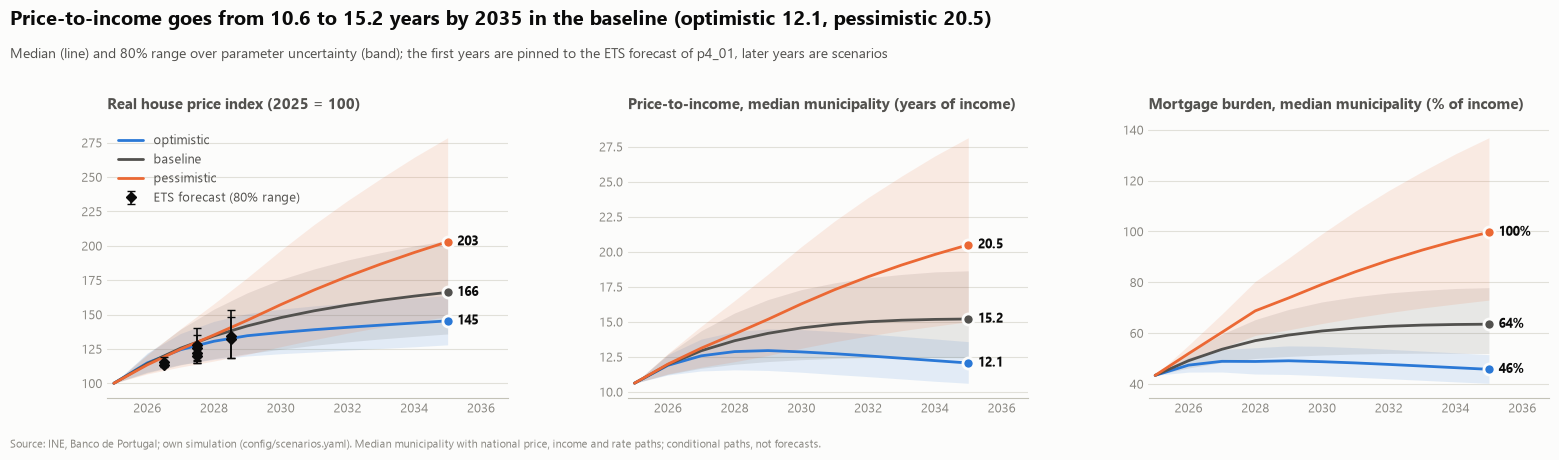

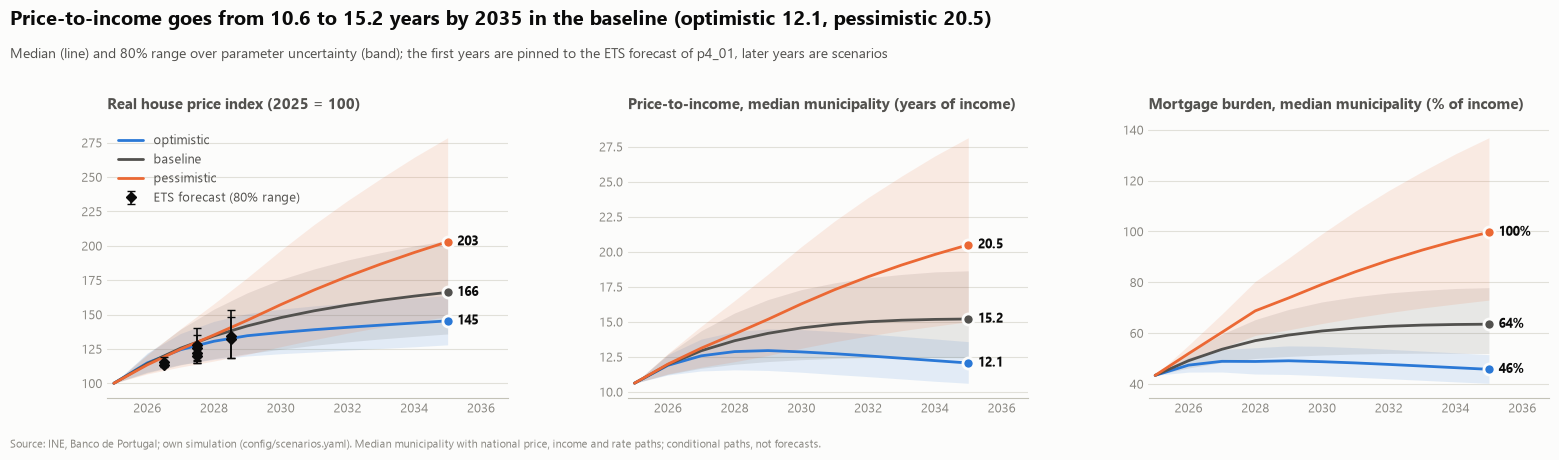

In [3]:
N, SEED = 1000, 2026
p = E.draw(A, N, SEED)
drift = E.calibrate(A, anc, p)
runs = {s: E.run(A, anc, s, None, p, drift) for s in A.scenarios}
bands = {
    m: {s: r.summary(m) for s, r in runs.items()}
    for m in ("price_index", "pti_years", "burden_pct")
}
long = pd.concat(
    [b.assign(scenario=s, metric=m) for m, d in bands.items() for s, b in d.items()],
    ignore_index=True,
)
style.save_table(long.round(3), "p4", "scenario_paths")

forecast_real = forecast[forecast["series"] == "Real house price index"].copy()
hpi_start = (
    nat.assign(year=pd.to_datetime(nat["period_start"]).dt.year)
    .groupby("year")["hpi_total_real_b2025"]
    .mean()[A.start_year]
)
ref_years = forecast_real["period"].str[:4].astype(float) + 0.5
reference = {
    "years": ref_years.to_numpy(),
    "mean": (100 * forecast_real["mean"] / hpi_start).to_numpy(),
    "lo80": (100 * forecast_real["lo80"] / hpi_start).to_numpy(),
    "hi80": (100 * forecast_real["hi80"] / hpi_start).to_numpy(),
}
fig = charts.scenario_fans(
    [
        {
            "title": f"Real house price index ({A.start_year} = 100)",
            "unit_fmt": "{:.0f}",
            "bands": bands["price_index"],
        },
        {
            "title": "Price-to-income, median municipality (years of income)",
            "unit_fmt": "{:.1f}",
            "bands": bands["pti_years"],
        },
        {
            "title": "Mortgage burden, median municipality (% of income)",
            "unit_fmt": "{:.0f}%",
            "bands": bands["burden_pct"],
        },
    ],
    reference=reference,
    headline=(
        f"Price-to-income goes from {anc.pti_years:.1f} to {bands['pti_years']['baseline']['p50'].iloc[-1]:.1f} years by {A.end_year} in the baseline "
        f"(optimistic {bands['pti_years']['optimistic']['p50'].iloc[-1]:.1f}, pessimistic {bands['pti_years']['pessimistic']['p50'].iloc[-1]:.1f})"
    ),
)
style.save_fig(fig, "p4", "scenario_fans")
fig

The black diamonds are the ETS forecast (quarterly, 2026Q3 to 2028Q2, rebased to the 2025 mean). The baseline median goes
through the last one by construction; the bands narrow there only to the forecast's own width.

In [4]:
end = pd.DataFrame(
    {
        s: {
            "real price, % vs start": np.median(r.end("price_index")) - 100,
            "PTI (median)": np.median(r.end("pti_years")),
            "PTI 10th pct": np.quantile(r.end("pti_years"), 0.1),
            "PTI 90th pct": np.quantile(r.end("pti_years"), 0.9),
            "burden % (median)": np.median(r.end("burden_pct")),
            "cumulative shortfall, households": np.median(r.end("cumulative_shortfall_n")),
        }
        for s, r in runs.items()
    }
).T.round(2)
style.save_table(end.reset_index(names="scenario"), "p4", "scenario_end_year")
end

,"real price, % vs start",PTI (median),PTI 10th pct,PTI 90th pct,burden % (median),"cumulative shortfall, households"
optimistic,45.39,12.06,10.61,13.58,45.75,-220729.74
baseline,66.13,15.20,12.43,18.64,63.50,19657.15
pessimistic,102.92,20.50,15.00,28.14,99.71,334277.43


## Step 3 — What do the policy levers do? (baseline scenario)
Illustrative sizes from 2027: 10,000 extra completions a year, 10,000 renovated vacant homes, 5,000 public homes, an IMI cut
of 0.05 pp (about 15% of the average bill), an IMT cut of 1 pp. Gain = fall in price-to-income in 2035 against no policy
(positive is better), with the cumulative budget cost. Tax cuts are scored on their price effect only, which is the
behavioural half of their effect; the saving to owners and the revenue they cost are shown separately.

,label,pti_gain_p10,pti_gain_p50,pti_gain_p90,price_effect_pct_p50,cost_bn,gain_per_bn_p50,share_improving
0,"10,000 extra homes a year",0.192,0.274,0.371,-1.788,2.871,0.095,1.0
1,"10,000 vacant homes renovated a year",0.235,0.323,0.443,-2.138,4.930,0.066,1.0
2,"5,000 public homes a year",0.116,0.161,0.222,-1.071,7.126,0.023,1.0
3,"Supply mix (5,000 + 5,000 + 2,500)",0.282,0.379,0.499,-2.505,7.481,0.051,1.0
4,IMI cut of 0.05 pp,-0.115,-0.069,-0.028,0.453,2.288,-0.030,0.0
5,IMT cut of 1 pp,-0.123,-0.077,-0.035,0.514,2.650,-0.029,0.0


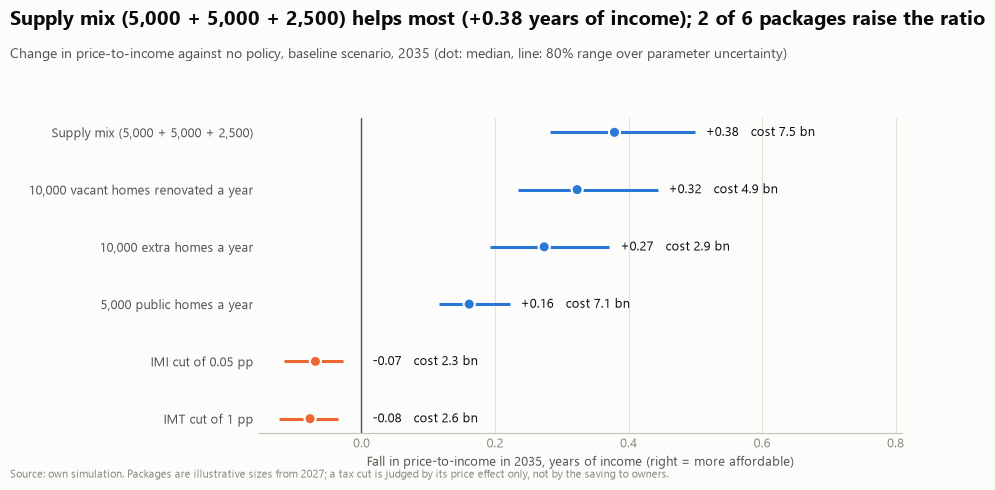

In [5]:
labels = {
    "construction": "10,000 extra homes a year",
    "renovation": "10,000 vacant homes renovated a year",
    "public": "5,000 public homes a year",
    "supply_mix": "Supply mix (5,000 + 5,000 + 2,500)",
    "imi_cut": "IMI cut of 0.05 pp",
    "imt_cut": "IMT cut of 1 pp",
}
rows = []
for name, label in labels.items():
    c = E.compare(A, anc, "baseline", E.Policy.package(A, name), p)
    s = E.summarise(c)
    rows.append(
        {"package": name, "label": label, **s.to_dict(), "cost_bn": s["cost_eur_p50"] / 1e9}
    )
effects = pd.DataFrame(rows)
style.save_table(effects.round(4), "p4", "policy_effects_baseline")
fig = charts.policy_effects(effects, A.end_year)
style.save_fig(fig, "p4", "policy_effects")
effects[
    [
        "label",
        "pti_gain_p10",
        "pti_gain_p50",
        "pti_gain_p90",
        "price_effect_pct_p50",
        "cost_bn",
        "gain_per_bn_p50",
        "share_improving",
    ]
].round(3)

### The IMI lever at both ends
Phase 3 could not pin down capitalisation (every interval contains zero and full capitalisation), so the lever is run at
no capitalisation and at full capitalisation instead of with an estimate. At no capitalisation the cut changes nothing in
prices and only costs revenue (an owner's saving, not in this indicator); at full capitalisation it lifts prices
by the p3 benchmark.

In [6]:
imi = []
for share in (0.0, 1.0):
    pm = E.central(A, **{"imi_reform__capitalisation_share": share})
    c = E.compare(A, anc, "baseline", E.Policy.package(A, "imi_cut"), pm)
    imi.append(
        {
            "capitalisation": share,
            "price_effect_pct": c["price_effect_pct"].iloc[0],
            "pti_gain": c["pti_gain"].iloc[0],
            "budget_cost_bn": c["cost_eur"].iloc[0] / 1e9,
        }
    )
imi = pd.DataFrame(imi)
style.save_table(imi.round(4), "p4", "imi_bounds")
imi

,capitalisation,price_effect_pct,pti_gain,budget_cost_bn
0,0.0,0.0000,0.000000,2.287969
1,1.0,0.9375,-0.142961,2.287969


## Step 4 — Same package, different futures
Does the ranking of the levers depend on the scenario? Gain in 2035 for each package under the three scenarios.

In [7]:
table = E.scenario_table(A, anc, p)
style.save_table(table.round(3), "p4", "scenario_by_package")
gain = []
for s in A.scenarios:
    for name in labels:
        c = E.compare(A, anc, s, E.Policy.package(A, name), p)
        gain.append({"scenario": s, "package": name, "gain_p50": c["pti_gain"].median()})
gain = pd.DataFrame(gain).pivot(index="package", columns="scenario", values="gain_p50")[
    list(A.scenarios)
]
style.save_table(gain.round(3).reset_index(), "p4", "policy_gain_by_scenario")
gain.round(3)

scenario,optimistic,baseline,pessimistic
package,,,
construction,0.222,0.274,0.357
imi_cut,-0.054,-0.069,-0.090
imt_cut,-0.061,-0.077,-0.102
public,0.132,0.161,0.213
renovation,0.261,0.323,0.425
supply_mix,0.306,0.379,0.497


## Step 5 — Sensitivity (RQ10.6)
Each input moves alone from its low to its high value, with all others at their central value. Behavioural parameters are
recalibrated to the forecast each time. Scenario inputs span the range between the three scenarios.

,parameter,kind,low_pti_end,high_pti_end,swing_pti_end,swing_pti_gain
0,other_demand_half_life_years,scenario,13.02,19.11,6.10,0.15
1,net_migration_per_year,scenario,14.46,16.46,2.00,0.03
2,mortgage_rate_pct,scenario,15.71,14.51,1.21,0.03
3,household_income_growth_real_pct,scenario,15.63,14.88,0.75,0.02
4,completions_per_year,scenario,15.61,14.87,0.74,0.02
5,income_elasticity_of_price,behaviour,14.94,15.56,0.62,0.02
6,usable_share_of_additions,behaviour,15.37,15.13,0.24,0.04
7,price_flexibility_balance,behaviour,15.24,15.26,0.01,0.25
8,mortgage_rate_semi_elasticity,behaviour,15.24,15.26,0.01,0.00
9,construction_boost.additionality,behaviour,15.25,15.25,0.00,0.09


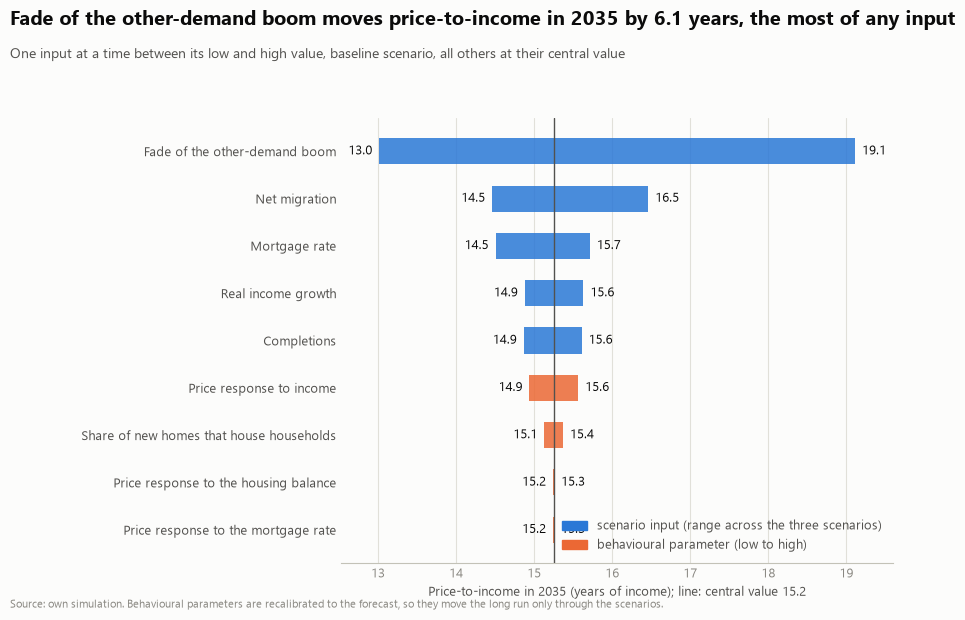

In [8]:
sens = E.sensitivity(A, anc, "baseline", E.Policy.package(A, "supply_mix"))
style.save_table(sens.round(3), "p4", "sensitivity")
base_pti = E.run(A, anc, "baseline").end("pti_years")[0]
fig = charts.sensitivity_tornado(sens, base_pti, A.end_year)
style.save_fig(fig, "p4", "sensitivity_tornado")
sens[["parameter", "kind", "low_pti_end", "high_pti_end", "swing_pti_end", "swing_pti_gain"]].round(
    2
)

## Step 6 — Best mix under a budget (RQ10.5)
Every split of an annual budget over the five levers in steps of 25%, for budgets of 0.5, 1 and 2 billion EUR a year
from 2027 (units at mid cost; tax cuts sized so that their revenue loss equals their share). Ranked by the median fall in
price-to-income in 2035.

In [9]:
mixes = []
for budget in (0.5e9, 1e9, 2e9):
    m = E.mix_search(A, anc, "baseline", budget, p)
    mixes.append(m.assign(budget_bn_a_year=budget / 1e9))
mixes = pd.concat(mixes, ignore_index=True)
style.save_table(mixes.round(4), "p4", "budget_mixes")
top = mixes.groupby("budget_bn_a_year").head(5)
top.round(3)

,share_construction_boost_units,share_vacant_renovation_units,share_public_housing_units,share_imi_rate_change_pp,share_imt_rate_change_pp,pti_gain_p10,pti_gain_p50,pti_gain_p90,share_improving,cost_eur_p50,budget_bn_a_year
0,1.00,0.00,0.00,0.0,0.0,0.382,0.542,0.734,1.0,5.741420e+09,0.5
1,0.75,0.25,0.00,0.0,0.0,0.354,0.488,0.655,1.0,5.552720e+09,0.5
2,0.75,0.00,0.25,0.0,0.0,0.308,0.433,0.588,1.0,5.449496e+09,0.5
3,0.50,0.50,0.00,0.0,0.0,0.317,0.431,0.577,1.0,5.413781e+09,0.5
4,0.50,0.25,0.25,0.0,0.0,0.277,0.379,0.505,1.0,5.267935e+09,0.5
70,1.00,0.00,0.00,0.0,0.0,0.752,1.065,1.438,1.0,1.148284e+10,1.0
71,0.75,0.25,0.00,0.0,0.0,0.698,0.959,1.286,1.0,1.110544e+10,1.0
72,0.75,0.00,0.25,0.0,0.0,0.609,0.853,1.155,1.0,1.089899e+10,1.0
73,0.50,0.50,0.00,0.0,0.0,0.627,0.849,1.135,1.0,1.082756e+10,1.0
74,0.50,0.25,0.25,0.0,0.0,0.548,0.750,0.997,1.0,1.053587e+10,1.0


### How much does the ranking depend on the unit costs?
The mixes put the whole budget into one lever because the model is linear in every lever, so the ranking is the ranking of
gain per euro, and the unit costs are the weakest numbers (assumptions, not estimates). Gain per billion euros with each
lever's unit cost at its low, mid and high value (others at mid).

In [10]:
cost_check = []
for pkg, key in (
    ("construction", "construction_boost.cost_per_unit_eur"),
    ("renovation", "vacant_renovation.cost_per_unit_eur"),
    ("public", "public_housing.cost_per_unit_eur"),
):
    for which in ("low", "mid", "high"):
        pm = E.central(A, **{key: A.ranges[key].at(which)})
        c = E.compare(A, anc, "baseline", E.Policy.package(A, pkg), pm)
        cost_check.append(
            {
                "package": pkg,
                "unit_cost": which,
                "unit_cost_eur": A.ranges[key].at(which),
                "gain_per_bn": c["gain_per_bn"].iloc[0],
            }
        )
cost_check = pd.DataFrame(cost_check)
style.save_table(cost_check.round(4), "p4", "unit_cost_check")
cost_check.pivot(index="package", columns="unit_cost", values="gain_per_bn")[
    ["low", "mid", "high"]
].round(3)

unit_cost,low,mid,high
package,,,
construction,0.250,0.120,0.050
public,0.073,0.023,0.015
renovation,0.214,0.073,0.036


## What this says
See `reports/p4_forecast.md` for the reading, the limits and what to carry into the dashboard page. Parameters, scenario
paths and every table are in `reports/tables/p4/`.